# Práctica de Clustering

Integrantes del grupo:

- Anton Pogromskyy Mozharsky
- Diego Mateo Fernandez
- Oliver Anderson Llorens (oliver.anderson@alumnos.upm.es)

En esta práctica, aplicaremos los conceptos de clustering impartidos en un dataset de nuestra elección.

## Exploración de los datos

Primero, cargamos el archivo con los datos para analizarlo. En este trabajo utilizamos el dataset [Customer Personality Analysis](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis), publicado en Kaggle. 

El objetivo es explorar si existen grupos de clientes con comportamientos de compra similares.

In [19]:
import pandas as pd

df = pd.read_csv("data/marketing_campaign.csv", sep="\t")

print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Filas: 2240 | Columnas: 29


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


Contiene 2.240 registros y 29 variables. Cada fila representa a un cliente e incluye información sobre su perfil demográfico, sus hábitos de compra y su respuesta a campañas de marketing.


| Columna o grupo | Significado |
| --- | --- |
| `ID` | Identificador del cliente. |
| `Year_Birth` | Año de nacimiento. |
| `Education`, `Marital_Status` | Nivel educativo y estado civil, respectivamente. |
| `Income` | Ingresos anuales del hogar. |
| `Kidhome`, `Teenhome` | Número de niños y adolescentes en el hogar, respectivamente. |
| `Dt_Customer` | Fecha de alta como cliente. |
| `Recency` | Días transcurridos desde la última compra. |
| `Mnt*` | Importe gastado en los últimos dos años por categoría. El sufijo indica el producto, como `Wines` para vino o `Fruits` para fruta. |
| `NumDealsPurchases` | Número de compras realizadas con descuento. |
| `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases` | Número de compras por web, catálogo y tienda física, respectivamente. |
| `NumWebVisitsMonth` | Número de visitas a la web de la empresa en el último mes. |
| `AcceptedCmp1` a `AcceptedCmp5` | Indican si el cliente aceptó la oferta de cada campaña numerada (1 = sí, 0 = no). |
| `Complain` | Indica si el cliente presentó alguna reclamación en los últimos dos años (1 = sí, 0 = no). |
| `Z_CostContact`, `Z_Revenue` | Sus nombres hacen referencia al coste de contacto y a los ingresos, respectivamente. La ficha del dataset no explica cómo se definen. |
| `Response` | Indica si el cliente aceptó la oferta de la última campaña (1 = sí, 0 = no). |

In [20]:
resumen_columnas = pd.DataFrame({
    "tipo": df.dtypes,
    "valores_ausentes": df.isna().sum(),
    "valores_distintos": df.nunique()
})

resumen_columnas

,tipo,valores_ausentes,valores_distintos
ID,int64,0,2240
Year_Birth,int64,0,59
Education,str,0,5
Marital_Status,str,0,8
Income,float64,24,1974
Kidhome,int64,0,3
Teenhome,int64,0,3
Dt_Customer,str,0,663
Recency,int64,0,100
MntWines,int64,0,776


De primeras, observamos que `Income` es la única variable que tiene valores ausentes. Al ser relativamente pocos, deberíamos ver cómo tratarlos de usar la variable. `ID` identifica a cada fila, con lo que lo conservaremos para identificar los registros pero debemos de eliminarlo a la hora de hacer clustering. `Z_CostContact` y `Z_Revenue` son constantes, por lo que podemos excluirlas. `Dt_Customer` es una fecha, pero se ha leído como texto, por lo que tenemos que convertirla a formato fecha. Por último, vemos como la variable que usaremos como predicción es `Response`.

In [21]:
columnas_excluir = ["ID", "Z_CostContact", "Z_Revenue"]

resumen_numerico = (
    df.drop(columns=columnas_excluir)
    .select_dtypes(include="number")
    .describe()
    .T
    .round(2)
)

resumen_numerico

,count,mean,std,min,25%,50%,75%,max
Year_Birth,2240.0,1968.81,11.98,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.44,0.54,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.51,0.54,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.94,336.60,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.30,39.77,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.95,225.72,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.53,54.63,0.0,3.00,12.0,50.00,259.0
MntSweetProducts,2240.0,27.06,41.28,0.0,1.00,8.0,33.00,263.0


Excluímos el ID y las constantes, y analizamos el comportamiento estadístico de las demás variables. Lo que destaca es el `Income`, que tiene un máximo de 666.666, pero su tercer cuartil es 68.522. El mínimo en `Year_Birth` es 1893, por lo que habría que mirar si existen casos de este tipo y como tratarlos, ya que al ser el dataset va desde 2012 a 2014, por lo que no es del todo imposible que alguien de ese año se registrase, pero si sería muy raro.

In [22]:
columnas_revision = [
    "ID", "Year_Birth", "Dt_Customer", "Income",
    "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"
]

print("Los cinco ingresos más altos")
display(df.nlargest(5, "Income")[columnas_revision])

print("Los cinco años de nacimiento más antiguos")
display(df.nsmallest(5, "Year_Birth")[columnas_revision])

Los cinco ingresos más altos


,ID,Year_Birth,Dt_Customer,Income,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
2233,9432,1977,02-06-2013,666666.0,3,1,3
617,1503,1976,03-06-2013,162397.0,0,0,1
687,1501,1982,04-08-2012,160803.0,0,28,1
1300,5336,1971,04-06-2013,157733.0,1,0,1
164,8475,1973,01-03-2014,157243.0,0,22,0


Los cinco años de nacimiento más antiguos


,ID,Year_Birth,Dt_Customer,Income,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
239,11004,1893,17-05-2014,60182.0,1,0,2
339,1150,1899,26-09-2013,83532.0,4,6,4
192,7829,1900,26-09-2013,36640.0,2,1,2
1950,6663,1940,08-07-2013,51141.0,3,1,4
424,6932,1941,13-04-2013,93027.0,7,10,5


Vemos que el ingreso más alto es cuatro veces mayor aproximadamente al segundo más alto. Es un caso aislado que conviene tener en cuenta. Tenemos registros de fecha de nacimiento den 1893, 1899 y 1900, que implica edades superiores a 110 años. El siguiente cliente más antiguo es 1940, por lo que los tres valores anteriores son poco plausibles. Vemos que hay clientes con un numero elevado de compras de catálogo (28, 22, 10) frente a la mediana (2). Esto es importante para darse cuenta de como los métodos de clustering podrían estar en un futuro agrupando los datos.

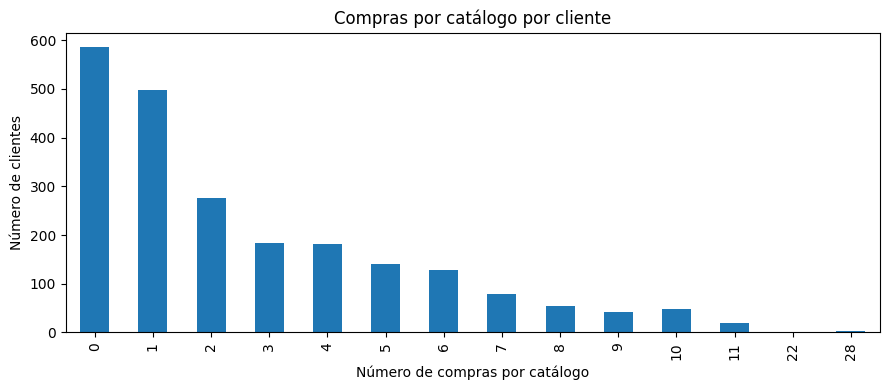

In [23]:
import matplotlib.pyplot as plt

compras_catalogo = df["NumCatalogPurchases"]

compras_catalogo.value_counts().sort_index().plot.bar(figsize=(9, 4))
plt.xlabel("Número de compras por catálogo")
plt.ylabel("Número de clientes")
plt.title("Compras por catálogo por cliente")
plt.tight_layout()
plt.show()

La mayoría de clientes están entre 0 y 2 compras, y los valores altos de 22 y 28 aparecen de forma aislada, pero no dejan de ser válidos, lo que habrá que comprobar como influyen.

In [24]:
variables_numericas = df.select_dtypes(include="number")
correlaciones = variables_numericas.corr(method="spearman")

correlaciones.style.format(precision=2, na_rep="—").background_gradient(
    cmap="RdBu_r", vmin=-1, vmax=1, axis=None
)

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
ID,1.00,0.00,0.00,0.00,-0.00,-0.05,-0.03,-0.02,-0.01,-0.03,-0.03,-0.04,-0.02,-0.02,-0.01,-0.02,-0.01,-0.04,-0.03,-0.01,-0.02,-0.02,0.03,—,—,-0.02
Year_Birth,0.00,1.00,-0.22,0.26,-0.39,-0.02,-0.23,-0.03,-0.11,-0.03,0.00,-0.08,-0.09,-0.16,-0.18,-0.17,0.13,0.06,-0.07,0.01,-0.01,-0.01,-0.01,—,—,0.02
Income,0.00,-0.22,1.00,-0.56,0.05,0.01,0.83,0.58,0.82,0.58,0.57,0.51,-0.20,0.57,0.79,0.73,-0.64,-0.01,0.22,0.40,0.33,0.11,-0.03,—,—,0.16
Kidhome,0.00,0.26,-0.56,1.00,-0.05,0.01,-0.58,-0.45,-0.55,-0.45,-0.44,-0.43,0.26,-0.42,-0.60,-0.56,0.48,0.02,-0.16,-0.21,-0.18,-0.08,0.04,—,—,-0.08
Teenhome,-0.00,-0.39,0.05,-0.05,1.00,0.01,0.11,-0.20,-0.13,-0.23,-0.20,-0.02,0.48,0.15,-0.04,0.08,0.11,-0.05,0.04,-0.20,-0.15,-0.02,0.00,—,—,-0.16
Recency,-0.05,-0.02,0.01,0.01,0.01,1.00,0.02,0.03,0.03,0.01,0.02,0.02,0.01,-0.00,0.03,0.01,-0.02,-0.03,0.02,0.00,-0.02,-0.00,0.01,—,—,-0.20
MntWines,-0.03,-0.23,0.83,-0.58,0.11,0.02,1.00,0.52,0.82,0.52,0.51,0.58,0.06,0.74,0.82,0.81,-0.39,0.03,0.31,0.37,0.30,0.14,-0.04,—,—,0.20
MntFruits,-0.02,-0.03,0.58,-0.45,-0.20,0.03,0.52,1.00,0.71,0.71,0.69,0.57,-0.11,0.47,0.63,0.58,-0.44,0.01,0.03,0.24,0.18,0.00,-0.01,—,—,0.15
MntMeatProducts,-0.01,-0.11,0.82,-0.55,-0.13,0.03,0.82,0.71,1.00,0.73,0.70,0.64,-0.03,0.68,0.85,0.78,-0.49,0.01,0.14,0.33,0.29,0.06,-0.03,—,—,0.22
MntFishProducts,-0.03,-0.03,0.58,-0.45,-0.23,0.01,0.52,0.71,0.73,1.00,0.70,0.57,-0.12,0.47,0.66,0.58,-0.46,-0.02,0.01,0.22,0.21,-0.00,-0.03,—,—,0.12


Al ser un heatmap tan grande es difícil poder interpretarla bien, pero podemos ver que en la actividad de compra, los clientes con mayores ingresos tienden a gastar mas, y quienes compran por catálogo o tienda también tienden a gastar más. La recencia tiene correlaciones débiles con el resto, y las visitas a la web se relacionan negativamente con los ingresos y compras por catálogo.

## Preprocesado de los datos

In [25]:
columnas_excluir = ["ID", "Z_CostContact", "Z_Revenue", "Response"]

X = df.drop(columns=columnas_excluir).copy()

print(f"Clientes: {X.shape[0]} | Variables candidatas: {X.shape[1]}")
X.head()

Clientes: 2240 | Variables candidatas: 25


,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain
0,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,...,8,10,4,7,0,0,0,0,0,0
1,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,...,1,1,2,5,0,0,0,0,0,0
2,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,...,8,2,10,4,0,0,0,0,0,0
3,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,...,2,0,4,6,0,0,0,0,0,0
4,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,...,5,3,6,5,0,0,0,0,0,0


Vamos a preparar la fecha.

In [26]:
fechas_alta = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
fecha_referencia = fechas_alta.max()

X["AntiguedadDias"] = (fecha_referencia - fechas_alta).dt.days
X = X.drop(columns="Dt_Customer", errors="ignore")

print(f"Fecha de referencia: {fecha_referencia:%d/%m/%Y}")
X[["AntiguedadDias"]].head()

Fecha de referencia: 29/06/2014


,AntiguedadDias
0,663
1,113
2,312
3,139
4,161


Así convertimos en número de días par que se pueda usar en el clustering, tomando como referencia la fecha más reciente. 

In [27]:
mediana_ingresos = df["Income"].median()
X["Income"] = df["Income"].fillna(mediana_ingresos)

print(f"Mediana utilizada: {mediana_ingresos:.2f}")
print(f"Ingresos ausentes después de imputar: {X['Income'].isna().sum()}")

Mediana utilizada: 51381.50
Ingresos ausentes después de imputar: 0


Decidimos rellenar los valores ausentes de los ingresos con la mediana, ya que un valor extremo influiría mucho menos en ella que la media. Hacemos lo mismo con las edades atípicas.

In [28]:
X["Income"] = X["Income"].mask(
    X["Income"].eq(666666), mediana_ingresos
)

fecha_atipica = X["Year_Birth"].isin([1893, 1899, 1900])
mediana_nacimiento = X.loc[~fecha_atipica, "Year_Birth"].median()
X["Year_Birth"] = X["Year_Birth"].mask(fecha_atipica, mediana_nacimiento)

print("Ingreso extremo")
caso_ingreso = df["Income"].eq(666666)
display(pd.DataFrame({
    "Antes": df.loc[caso_ingreso, "Income"],
    "Después": X.loc[caso_ingreso, "Income"],
}))

print("Años de nacimiento atípicos")
casos_nacimiento = df["Year_Birth"].isin([1893, 1899, 1900])
display(pd.DataFrame({
    "Antes": df.loc[casos_nacimiento, "Year_Birth"],
    "Después": X.loc[casos_nacimiento, "Year_Birth"],
}))

Ingreso extremo


,Antes,Después
2233,666666.0,51381.5


Años de nacimiento atípicos


,Antes,Después
192,1900,1970
239,1893,1970
339,1899,1970


Como hemos visto, tenemos variables categóricas. Hace falta codificarlas en variables númericas, usando One-hot. Las variables que manipularemos serán educación y estado civil.

In [29]:
columnas_categoricas = ["Education", "Marital_Status"]

X_codificado = pd.get_dummies(
    X,
    columns=columnas_categoricas,
    dtype=int
)

X_codificado.filter(regex=r"^(Education|Marital_Status)_").head()

,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0,0,1,0,0,0,0,0,0,1,0,0,0
1,0,0,1,0,0,0,0,0,0,1,0,0,0
2,0,0,1,0,0,0,0,0,0,0,1,0,0
3,0,0,1,0,0,0,0,0,0,0,1,0,0
4,0,0,0,0,1,0,0,0,1,0,0,0,0


Los ingresos, días, recuentos de compras y demás tienen rangos de valores muy diferentes, por lo que conviene estandarizar la escala. Vamos a escalar todos con StandardScaler y a `Income` previamente uno logarítmico, para comprimir esas diferencias tan grandes.

In [30]:
import numpy as np
from sklearn.preprocessing import StandardScaler

columnas_numericas = X.select_dtypes(include="number").columns
columnas_escalar = [
    columna for columna in columnas_numericas
    if X[columna].nunique() > 2
]

X_preprocesado = X_codificado.copy()
X_preprocesado["Income"] = np.log1p(X_preprocesado["Income"])

escalador = StandardScaler()
X_preprocesado[columnas_escalar] = escalador.fit_transform(
    X_preprocesado[columnas_escalar]
)

X_preprocesado[columnas_escalar].head().round(2)

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AntiguedadDias
0,-1.02,0.43,-0.83,-0.93,0.31,0.98,1.55,1.68,2.46,1.48,0.84,0.35,1.41,2.51,-0.55,0.69,1.53
1,-1.27,-0.02,1.03,0.91,-0.38,-0.87,-0.64,-0.71,-0.65,-0.63,-0.73,-0.17,-1.11,-0.57,-1.17,-0.13,-1.19
2,-0.33,0.85,-0.83,-0.93,-0.80,0.36,0.57,-0.18,1.35,-0.15,-0.04,-0.69,1.41,-0.23,1.30,-0.54,-0.21
3,1.29,-1.13,1.03,-0.93,-0.80,-0.87,-0.56,-0.65,-0.50,-0.58,-0.75,-0.17,-0.75,-0.91,-0.55,0.28,-1.06
4,1.03,0.44,1.03,-0.93,1.55,-0.39,0.42,-0.22,0.16,-0.00,-0.56,1.38,0.33,0.12,0.06,-0.13,-0.95


Como hemos observado a lo largo de la práctica, hay una gran cantidad de variables, por lo que sería interesante reducirlas. Además, tenemos variables correlacionadas, por lo que emplearemos un algoritmo de FSS para reducir el número de variables. En este caso, probamos SBS, usando K-means para comparar los subconjuntos. También usaremos el silhouette score para guiar la búsqueda. Fijamos k=3 de forma provisional. 

In [32]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_sbs = 3

bloques = {}
for variable in X.columns:
    if variable in columnas_categoricas:
        bloques[variable] = [
            columna for columna in X_preprocesado.columns
            if columna.startswith(f"{variable}_")
        ]
    else:
        bloques[variable] = [variable]

muestra = X_preprocesado.sample(n=600, random_state=42)


def evaluar_subconjunto(variables):
    columnas = [
        columna
        for variable in variables
        for columna in bloques[variable]
    ]
    datos = X_preprocesado[columnas]

    if len(datos.drop_duplicates()) < k_sbs:
        return float("-inf")

    modelo = KMeans(n_clusters=k_sbs, n_init=10, random_state=42)
    etiquetas = modelo.fit_predict(datos)
    etiquetas_muestra = pd.Series(etiquetas, index=datos.index).loc[muestra.index]

    if etiquetas_muestra.nunique() < k_sbs:
        return float("-inf")

    return silhouette_score(muestra, etiquetas_muestra)


seleccionadas = list(bloques)
puntuacion_actual = evaluar_subconjunto(seleccionadas)

historial = [{
    "variable_retirada": "Ninguna (punto de partida)",
    "variables_restantes": len(seleccionadas),
    "silhouette_referencia": puntuacion_actual,
}]

while len(seleccionadas) > 1:
    puntuaciones = {
        variable: evaluar_subconjunto([v for v in seleccionadas if v != variable])
        for variable in seleccionadas
    }

    mejor_retirada = max(puntuaciones, key=puntuaciones.get)
    mejor_puntuacion = puntuaciones[mejor_retirada]

    if mejor_puntuacion <= puntuacion_actual:
        break

    seleccionadas.remove(mejor_retirada)
    puntuacion_actual = mejor_puntuacion
    historial.append({
        "variable_retirada": mejor_retirada,
        "variables_restantes": len(seleccionadas),
        "silhouette_referencia": puntuacion_actual,
    })

print(f"Variables conservadas: {len(seleccionadas)} de {len(bloques)}")
print(", ".join(seleccionadas))
pd.DataFrame(historial).round(4)

Variables conservadas: 20 de 25
Education, Marital_Status, Kidhome, Teenhome, Recency, MntWines, MntMeatProducts, MntGoldProds, NumDealsPurchases, NumWebPurchases, NumCatalogPurchases, NumStorePurchases, NumWebVisitsMonth, AcceptedCmp3, AcceptedCmp4, AcceptedCmp5, AcceptedCmp1, AcceptedCmp2, Complain, AntiguedadDias


,variable_retirada,variables_restantes,silhouette_referencia
0,Ninguna (punto de partida),25,0.1752
1,Income,24,0.1770
2,MntFishProducts,23,0.1801
3,MntSweetProducts,22,0.1804
4,Year_Birth,21,0.1810
5,MntFruits,20,0.1817


Con k = 3, SBS conservó 20 de las 25 variables candidatas. Retiró `Income`, `MntFishProducts`, `MntSweetProducts`, `Year_Birth` y `MntFruits`. El *silhouette* de referencia pasó de 0,1752 a 0,1817. La mejora fue pequeña y la búsqueda se detuvo cuando ninguna retirada adicional aumentó la puntuación.